# NLP — Text Preprocessing
## Tokenization · Stemming · Lemmatization · Stopwords

**Learning objective:** Understand how raw text is transformed into useful linguistic units before it is passed to a machine-learning model.

This notebook follows an end-to-end, experiment-first workflow:

1. Understand the theory and intuition.
2. Create a small review dataset.
3. Inspect raw text and tokenize it.
4. Apply stemming and lemmatization.
5. investigate stopwords and negation.
6. Compare preprocessing strategies.
7. Build and evaluate a small sentiment-classification system.
8. Save the fitted pipeline and test inference.

> Important: preprocessing is task-dependent. There is no universal rule that every text dataset should be lowercased, stemmed, lemmatized, or stripped of stopwords.

# 1. Theory

## 1.1 What is text preprocessing?

Text preprocessing is the set of operations used to transform raw text into a representation that is more suitable for a particular NLP task.

Example raw text:

`"The CATS were running quickly, and they weren't happy!"`

Possible transformations:

- Lowercasing: `the cats were running quickly, ...`
- Tokenization: `["the", "cats", "were", "running", ...]`
- Stemming: `running → run` (algorithm-dependent)
- Lemmatization: `cats → cat`, `were → be`
- Stopword filtering: optionally remove words such as `the`, `and`, `were`

The objective is not to make text look clean at any cost. The objective is to preserve useful information while reducing irrelevant variation.

## 1.2 The preprocessing pipeline

```text
Raw text
   |
   v
Normalization (optional: lowercase, Unicode handling)
   |
   v
Tokenization
   |
   +------> Stopword filtering (task-dependent)
   |
   +------> Stemming OR Lemmatization (task-dependent)
   |
   v
Processed tokens / text
   |
   v
Feature extraction (e.g., Bag of Words, TF-IDF, embeddings)
   |
   v
Machine-learning model
```

The order can vary. For example, stopword removal before lemmatization is common in simple pipelines, but retaining grammatical context or negation may be more important for some tasks.

## 1.3 Tokenization

Tokenization splits text into smaller units called tokens.

Common levels:

| Level | Example | Typical use |
|---|---|---|
| Sentence | A paragraph → sentences | Sentence-level analysis |
| Word | `NLP is useful` → `NLP`, `is`, `useful` | Classical NLP |
| Subword | `unbelievable` → pieces such as `un`, `believ`, `able` | Transformer tokenizers |
| Character | `cat` → `c`, `a`, `t` | Spelling/noisy-text tasks |

A token is not always identical to a word. Punctuation, contractions, hyphens, emojis, and languages without whitespace create tokenization challenges.

## 1.4 Stemming

Stemming reduces related word forms to a common stem by applying heuristic rules.

Examples (the exact result depends on the algorithm):

- `playing`, `played`, `plays` → `play`
- `connected`, `connecting` → `connect`
- `studies`, `studying` → algorithm-dependent stems

Stemming does not necessarily produce a valid dictionary word. It is usually faster and more mechanical than lemmatization.

Common algorithms:
- Porter Stemmer
- Snowball Stemmer
- Lancaster Stemmer

## 1.5 Lemmatization

Lemmatization maps an inflected word to its dictionary base form, called a lemma.

Examples:
- `am`, `are`, `is` → `be`
- `cars` → `car`
- `better` → `good` (with suitable lexical/POS information)
- `running` → `run`

A lemmatizer may need the word's part of speech. For example, `meeting` can be a noun or a verb. Context can change the correct lemma.

NLTK's WordNetLemmatizer defaults to noun treatment unless a POS tag is supplied. We will explicitly provide POS information in this notebook.

## 1.6 Stopwords

Stopwords are frequent words that are sometimes removed because they contribute little to a particular task.

Examples often include:
- `the`, `a`, `an`
- `is`, `are`, `was`
- `and`, `or`

But frequency does not mean unimportant.

**Critical sentiment example:**
- `This is good`
- `This is not good`

If `not` is removed, the meaning can be reversed. Therefore, blindly removing all stopwords can damage sentiment classification, intent detection, and other tasks where function words matter.

## 1.7 Stemming vs Lemmatization

| Aspect | Stemming | Lemmatization |
|---|---|---|
| Method | Heuristic suffix/prefix rules | Vocabulary and linguistic analysis |
| Output | May not be a valid word | Usually a dictionary lemma |
| Context/POS | Usually not required | Often improves results |
| Speed | Usually faster | Usually slower |
| Example | `studies → studi` (Porter may produce this) | `studies → study` |
| Best fit | Fast retrieval / rough normalization | Tasks needing linguistically meaningful forms |

Neither technique is always better. Evaluate them on the task.

## 1.8 Important assumptions and pitfalls

1. Tokenization depends on language, domain, punctuation, and task.
2. Lowercasing may erase useful information, such as `US` versus `us`.
3. Stemming can merge words that have different meanings.
4. Lemmatization can be wrong when POS/context is wrong.
5. Stopword removal can destroy negation, emphasis, or intent.
6. Preprocessing must be identical at training and inference.
7. Never fit data-dependent transformations using test data.

# 2. Math and formal intuition

Preprocessing is often a deterministic mapping from a text string to a sequence of tokens.

Let a document be:

\[
d = (w_1, w_2, \ldots, w_n)
\]

A tokenizer maps the string to a token sequence:

\[
T(d) = (t_1, t_2, \ldots, t_m)
\]

A normalization function \(N\) transforms each token, for example by lowercasing:

\[
N(t_i) = \operatorname{lower}(t_i)
\]

A stemmer \(S\) maps tokens to stems:

\[
S(t_i) = s_i
\]

A lemmatizer \(L\) maps a token and optionally its part of speech to a lemma:

\[
L(t_i, p_i) = \ell_i
\]

A stopword filter uses a set \(W\) and retains tokens not in that set:

\[
F(t_i) =
\begin{cases}
t_i & t_i \notin W\\
\varnothing & t_i \in W
\end{cases}
\]

The resulting processed document is a sequence of retained, normalized tokens.

**Key insight:** these transformations can discard information. They are useful only when the information removed is less important than the consistency or dimensionality they provide.

# 3. Setup and imports

Run this cell first. NLTK downloads small language resources used for tokenization, stopwords, POS tagging, and WordNet lemmatization.

If a managed environment blocks downloads, run the downloads in an environment with internet access or use the fallback tokenizer shown later.

In [1]:
%pip install -q nltk pandas numpy scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import re
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.tokenize import word_tokenize, sent_tokenize, TreebankWordTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer, WordNetLemmatizer
from nltk import pos_tag

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Download NLTK resources.
# punkt / punkt_tab: tokenization
# stopwords: stopword corpus
# wordnet / omw-1.4: lexical database for lemmatization
# averaged_perceptron_tagger_eng: POS tagging in recent NLTK versions

resources = [
    "punkt",
    "punkt_tab",
    "stopwords",
    "wordnet",
    "omw-1.4",
    "averaged_perceptron_tagger_eng",
]

for resource in resources:
    try:
        nltk.download(resource, quiet=True)
    except Exception as exc:
        print(f"Could not download {resource}: {exc}")

print("NLTK version:", nltk.__version__)

NLTK version: 3.10.3


# 4. Create a small illustrative dataset

We will use customer reviews because they make the effect of preprocessing easy to understand.

Labels:
- `1` = positive
- `0` = negative

This is a teaching dataset, not a benchmark. Its size is intentionally small, so model scores must not be interpreted as real-world performance.

In [4]:
positive_reviews = [
    "I love this product",
    "The quality is excellent",
    "Amazing experience and great service",
    "This product works perfectly",
    "Very happy with my purchase",
    "Excellent value for money",
    "The delivery was fast and easy",
    "Fantastic quality and performance",
    "I would definitely recommend it",
    "The product is wonderful",
    "Great experience from start to finish",
    "The service was helpful and friendly",
    "Really good product and reliable performance",
    "I am satisfied with the purchase",
    "Everything worked exactly as expected",
    "Brilliant product and excellent support",
    "The quality exceeded my expectations",
    "Very useful and easy to operate",
    "A great purchase overall",
    "I enjoyed using this product",
    "Fast delivery and great packaging",
    "This is one of my favorite products",
    "Works well and feels premium",
    "Excellent support from the company",
    "I am impressed with the quality",
    "The experience was smooth and pleasant",
    "Affordable and surprisingly good",
    "Very convenient and dependable",
    "I would buy this again",
    "The product is worth the price",
]

negative_reviews = [
    "I hate this product",
    "The quality is terrible",
    "Awful experience and poor service",
    "This product never works properly",
    "Very disappointed with my purchase",
    "Poor value for money",
    "The delivery was late and difficult",
    "Terrible quality and performance",
    "I would never recommend it",
    "The product is horrible",
    "A frustrating experience from start to finish",
    "The service was rude and unhelpful",
    "Really bad product and unreliable performance",
    "I am unhappy with the purchase",
    "Nothing worked as expected",
    "Poor product and terrible support",
    "The quality was below my expectations",
    "Very confusing and difficult to operate",
    "A bad purchase overall",
    "I regret using this product",
    "Late delivery and damaged packaging",
    "This is one of my least favorite products",
    "Works poorly and feels cheap",
    "No useful support from the company",
    "I am disappointed with the quality",
    "The experience was stressful and unpleasant",
    "Overpriced and surprisingly bad",
    "Very inconvenient and unreliable",
    "I would not buy this again",
    "The product is not worth the price",
]

texts = positive_reviews + negative_reviews
labels = np.array([1] * len(positive_reviews) + [0] * len(negative_reviews))

df = pd.DataFrame({
    "text": texts,
    "label": labels,
})

print("Dataset shape:", df.shape)
print("\\nClass distribution:")
print(df["label"].value_counts().sort_index())

df.head(10)

Dataset shape: (60, 2)
\nClass distribution:
label
0    30
1    30
Name: count, dtype: int64


,text,label
0,I love this product,1
1,The quality is excellent,1
2,Amazing experience and great service,1
3,This product works perfectly,1
4,Very happy with my purchase,1
5,Excellent value for money,1
6,The delivery was fast and easy,1
7,Fantastic quality and performance,1
8,I would definitely recommend it,1
9,The product is wonderful,1


# 5. Tokenization

## 5.1 Sentence tokenization

Sentence tokenization separates a paragraph into sentences.

In [5]:
paragraph = (
    "NLP is fascinating. Tokenization is an important first step! "
    "Can a computer understand language?"
)

sentences = sent_tokenize(paragraph)

print("Original paragraph:")
print(paragraph)

print("\\nSentences:")
for i, sentence in enumerate(sentences, start=1):
    print(f"{i}. {sentence}")

Original paragraph:
NLP is fascinating. Tokenization is an important first step! Can a computer understand language?
\nSentences:
1. NLP is fascinating.
2. Tokenization is an important first step!
3. Can a computer understand language?


## 5.2 Word tokenization

Word tokenization divides a sentence into word-like tokens. Notice how punctuation and contractions may be handled as separate tokens.

In [6]:
sample_text = "I am learning NLP, and I'm enjoying it!"

tokens = word_tokenize(sample_text)

print("Original text:", sample_text)
print("Tokens:", tokens)
print("Number of tokens:", len(tokens))

Original text: I am learning NLP, and I'm enjoying it!
Tokens: ['I', 'am', 'learning', 'NLP', ',', 'and', 'I', "'m", 'enjoying', 'it', '!']
Number of tokens: 11


## 5.3 Compare tokenizers

Different tokenizers make different decisions. `TreebankWordTokenizer` is a useful deterministic fallback that does not require downloading Punkt resources.

In [7]:
treebank_tokens = TreebankWordTokenizer().tokenize(sample_text)

print("NLTK word_tokenize:", word_tokenize(sample_text))
print("Treebank tokenizer:", treebank_tokens)

NLTK word_tokenize: ['I', 'am', 'learning', 'NLP', ',', 'and', 'I', "'m", 'enjoying', 'it', '!']
Treebank tokenizer: ['I', 'am', 'learning', 'NLP', ',', 'and', 'I', "'m", 'enjoying', 'it', '!']


## 5.4 Tokenization on our review dataset

In [8]:
df["tokens"] = df["text"].apply(word_tokenize)

display(df[["text", "tokens"]].head(8))

,text,tokens
0,I love this product,"[I, love, this, product]"
1,The quality is excellent,"[The, quality, is, excellent]"
2,Amazing experience and great service,"[Amazing, experience, and, great, service]"
3,This product works perfectly,"[This, product, works, perfectly]"
4,Very happy with my purchase,"[Very, happy, with, my, purchase]"
5,Excellent value for money,"[Excellent, value, for, money]"
6,The delivery was fast and easy,"[The, delivery, was, fast, and, easy]"
7,Fantastic quality and performance,"[Fantastic, quality, and, performance]"


### Tokenization pitfalls

- `can't` may be split into `ca` and `n't` depending on tokenizer.
- `New York` may need to remain a multiword entity for some tasks.
- URLs, hashtags, emojis, product codes, and misspellings need domain-aware handling.
- Word tokenization is not the same as subword tokenization used by many Transformer models.

# 6. Stemming

A stemmer applies heuristic rules to reduce word forms. Let's compare three popular NLTK stemmers.

In [9]:
words = [
    "playing", "played", "plays",
    "connected", "connecting", "connection",
    "studies", "studying", "study",
    "generously", "generation", "generational",
]

porter = PorterStemmer()
snowball = SnowballStemmer("english")
lancaster = LancasterStemmer()

stemming_comparison = pd.DataFrame({
    "word": words,
    "Porter": [porter.stem(w) for w in words],
    "Snowball": [snowball.stem(w) for w in words],
    "Lancaster": [lancaster.stem(w) for w in words],
})

display(stemming_comparison)

,word,Porter,Snowball,Lancaster
0,playing,play,play,play
1,played,play,play,play
2,plays,play,play,play
3,connected,connect,connect,connect
4,connecting,connect,connect,connect
5,connection,connect,connect,connect
6,studies,studi,studi,study
7,studying,studi,studi,study
8,study,studi,studi,study
9,generously,gener,generous,gen


## 6.1 Understand the algorithms

- **Porter:** classic rule-based stemmer; widely used as a baseline.
- **Snowball:** an improved family of stemmers; NLTK's English implementation is commonly called the Snowball stemmer.
- **Lancaster:** more aggressive; it may shorten words substantially.

Do not assume that a stem is a valid English word. A stemmer is not a dictionary.

In [10]:
sample_sentence = "The players were playing and played beautifully."

sample_tokens = word_tokenize(sample_sentence)

print("Original tokens:")
print(sample_tokens)

print("\\nPorter stems:")
print([porter.stem(token.lower()) for token in sample_tokens])

Original tokens:
['The', 'players', 'were', 'playing', 'and', 'played', 'beautifully', '.']
\nPorter stems:
['the', 'player', 'were', 'play', 'and', 'play', 'beauti', '.']


## 6.2 Stemming across the dataset

We will create a column containing Porter-stemmed tokens. Punctuation tokens are retained here to make the transformation visible; later, the project pipeline will use a more deliberate token filter.

In [11]:
def porter_stem_text(text):
    tokens = word_tokenize(text.lower())
    return [porter.stem(token) for token in tokens]

df["stemmed_tokens"] = df["text"].apply(porter_stem_text)

display(df[["text", "tokens", "stemmed_tokens"]].head(10))

,text,tokens,stemmed_tokens
0,I love this product,"[I, love, this, product]","[i, love, thi, product]"
1,The quality is excellent,"[The, quality, is, excellent]","[the, qualiti, is, excel]"
2,Amazing experience and great service,"[Amazing, experience, and, great, service]","[amaz, experi, and, great, servic]"
3,This product works perfectly,"[This, product, works, perfectly]","[thi, product, work, perfectli]"
4,Very happy with my purchase,"[Very, happy, with, my, purchase]","[veri, happi, with, my, purchas]"
5,Excellent value for money,"[Excellent, value, for, money]","[excel, valu, for, money]"
6,The delivery was fast and easy,"[The, delivery, was, fast, and, easy]","[the, deliveri, wa, fast, and, easi]"
7,Fantastic quality and performance,"[Fantastic, quality, and, performance]","[fantast, qualiti, and, perform]"
8,I would definitely recommend it,"[I, would, definitely, recommend, it]","[i, would, definit, recommend, it]"
9,The product is wonderful,"[The, product, is, wonderful]","[the, product, is, wonder]"


### Stemming pitfalls

- Different words can collapse to the same stem.
- Some stems are not valid words.
- Aggressive stemming can harm readability and semantic interpretation.
- Stemming is not always beneficial for sentiment classification; test it rather than assuming it helps.

# 7. Lemmatization

Lemmatization uses a lexical resource to return a base dictionary form. NLTK's `WordNetLemmatizer` uses WordNet.

## 7.1 Basic lemmatization

By default, WordNetLemmatizer treats a word as a noun (`pos='n'`). That is why POS information matters.

In [12]:
lemmatizer = WordNetLemmatizer()

lemma_words = ["cars", "running", "better", "was", "studies"]

basic_lemmas = [
    lemmatizer.lemmatize(word)
    for word in lemma_words
]

print("Words: ", lemma_words)
print("Lemmas:", basic_lemmas)

Words:  ['cars', 'running', 'better', 'was', 'studies']
Lemmas: ['car', 'running', 'better', 'wa', 'study']


## 7.2 Lemmatization with part-of-speech (POS)

WordNet uses these POS categories:
- `n` = noun
- `v` = verb
- `a` = adjective
- `r` = adverb

NLTK POS tagger uses a different tag set (Penn Treebank). We map its tags to WordNet categories.

In [13]:
def penn_to_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN  # sensible default for this demonstration


def pos_aware_lemmatize(text):
    tokens = word_tokenize(text.lower())
    tagged_tokens = pos_tag(tokens)
    lemmas = []
    for token, tag in tagged_tokens:
        wn_pos = penn_to_wordnet_pos(tag)
        lemma = lemmatizer.lemmatize(token, pos=wn_pos)
        lemmas.append(lemma)
    return lemmas

sentence = "The cats were running faster and the children were playing."

print("Tokens:")
print(word_tokenize(sentence.lower()))

print("\\nPOS tags:")
print(pos_tag(word_tokenize(sentence.lower())))

print("\\nPOS-aware lemmas:")
print(pos_aware_lemmatize(sentence))

Tokens:
['the', 'cats', 'were', 'running', 'faster', 'and', 'the', 'children', 'were', 'playing', '.']
\nPOS tags:
[('the', 'DT'), ('cats', 'NNS'), ('were', 'VBD'), ('running', 'VBG'), ('faster', 'RBR'), ('and', 'CC'), ('the', 'DT'), ('children', 'NNS'), ('were', 'VBD'), ('playing', 'VBG'), ('.', '.')]
\nPOS-aware lemmas:
['the', 'cat', 'be', 'run', 'faster', 'and', 'the', 'child', 'be', 'play', '.']


## 7.3 Compare stemming and lemmatization

In [15]:
comparison_words = [
    "studies", "studying", "running", "ran",
    "cars", "better", "was", "generously",
]

comparison = pd.DataFrame({
    "word": comparison_words,
    "Porter stem": [porter.stem(w) for w in comparison_words],
    "Snowball stem": [snowball.stem(w) for w in comparison_words],
    "Lemma as noun": [lemmatizer.lemmatize(w, pos="n") for w in comparison_words],
    "Lemma as verb": [lemmatizer.lemmatize(w, pos="v") for w in comparison_words],
    "Lemma as adjective": [lemmatizer.lemmatize(w, pos="a") for w in comparison_words],
})

display(comparison)

,word,Porter stem,Snowball stem,Lemma as noun,Lemma as verb,Lemma as adjective
0,studies,studi,studi,study,study,studies
1,studying,studi,studi,studying,study,studying
2,running,run,run,running,run,running
3,ran,ran,ran,ran,run,ran
4,cars,car,car,car,cars,cars
5,better,better,better,better,better,good
6,was,wa,was,wa,be,was
7,generously,gener,generous,generously,generously,generously


### Why POS-aware lemmatization matters

The word `meeting` can be:
- a noun: "The meeting was long."
- a verb form: "They are meeting today."

The correct lemma depends on grammatical role and context. POS tagging helps, but automatic tagging is not perfect, especially on short, noisy, or domain-specific text.

# 8. Stopwords

## 8.1 Load NLTK stopwords

NLTK provides a common English stopword list. The list is a starting point, not a universal truth.

In [16]:
stop_words = set(stopwords.words("english"))

print("Number of English stopwords:", len(stop_words))
print("Sample stopwords:", sorted(list(stop_words))[:30])

Number of English stopwords: 198
Sample stopwords: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't"]


## 8.2 Remove stopwords

In [17]:
sentence = "This is a very useful product and it works extremely well."

tokens = word_tokenize(sentence.lower())

filtered_tokens = [
    token for token in tokens
    if token.isalpha() and token not in stop_words
]

print("Original tokens:")
print(tokens)

print("\\nAfter stopword removal:")
print(filtered_tokens)

Original tokens:
['this', 'is', 'a', 'very', 'useful', 'product', 'and', 'it', 'works', 'extremely', 'well', '.']
\nAfter stopword removal:
['useful', 'product', 'works', 'extremely', 'well']


## 8.3 The negation problem: do not blindly remove stopwords

Consider:
- `The product is good`
- `The product is not good`

If `not` is removed, both sentences may become nearly identical.

For sentiment analysis, preserve negation terms. One simple approach is to remove stopwords except a small set of negators.

In [19]:
negation_words = {
    "no", "not", "nor", "never", "n't",
    "cannot", "without", "neither", "none"
}

stop_words_without_negation = stop_words - negation_words

examples = [
    "The product is good",
    "The product is not good",
    "I never liked the service",
]

for text in examples:
    tokens = word_tokenize(text.lower())

    naive = [
        t for t in tokens
        if t.isalpha() and t not in stop_words
    ]

    preserve_negation = [
        t for t in tokens
        if t.isalpha() and t not in stop_words_without_negation
    ]

    print("\\nText:", text)
    print("Naive removal:", naive)
    print("Negation preserved:", preserve_negation)

\nText: The product is good
Naive removal: ['product', 'good']
Negation preserved: ['product', 'good']
\nText: The product is not good
Naive removal: ['product', 'good']
Negation preserved: ['product', 'not', 'good']
\nText: I never liked the service
Naive removal: ['never', 'liked', 'service']
Negation preserved: ['never', 'liked', 'service']


### Stopword-removal pitfalls

- Negation (`not`, `never`) can reverse sentiment.
- Pronouns may matter for authorship, dialogue, or conversational intent.
- Prepositions can matter for relations and instructions.
- Frequent words can still carry meaning in some domains.
- A custom stopword list should be validated against the task and dataset.

# 9. Combine preprocessing operations

We will create reusable functions. The function below supports:
- lowercasing,
- word tokenization,
- optional stopword removal,
- optional stemming or lemmatization.

We deliberately keep negation by default. Punctuation is removed for this simple bag-of-words-style demonstration, but punctuation may be important for other tasks.

In [20]:
def preprocess_text(
    text,
    remove_stopwords=False,
    normalization="lemma",
    preserve_negation=True,
):
    # 1. Normalize case
    text = text.lower()

    # 2. Tokenize
    tokens = word_tokenize(text)

    # 3. Keep alphabetic tokens for this simple English review task
    tokens = [token for token in tokens if token.isalpha()]

    # 4. Optional stopword removal
    if remove_stopwords:
        active_stopwords = (
            stop_words_without_negation
            if preserve_negation
            else stop_words
        )
        tokens = [token for token in tokens if token not in active_stopwords]

    # 5. Apply one normalization method
    if normalization == "stem":
        tokens = [porter.stem(token) for token in tokens]

    elif normalization == "lemma":
        # POS tagging is performed on the remaining tokens.
        tagged = pos_tag(tokens)
        tokens = [
            lemmatizer.lemmatize(token, pos=penn_to_wordnet_pos(tag))
            for token, tag in tagged
        ]

    elif normalization == "none":
        pass

    else:
        raise ValueError("normalization must be 'none', 'stem', or 'lemma'")

    return tokens


demo = "The children were playing happily, but the service was not good."

print("Original:", demo)
print("Tokens:", preprocess_text(demo, normalization="none"))
print("Stemmed:", preprocess_text(demo, normalization="stem"))
print("Lemmatized:", preprocess_text(demo, normalization="lemma"))
print(
    "Lemma + stopwords removed:",
    preprocess_text(demo, remove_stopwords=True, normalization="lemma")
)

Original: The children were playing happily, but the service was not good.
Tokens: ['the', 'children', 'were', 'playing', 'happily', 'but', 'the', 'service', 'was', 'not', 'good']
Stemmed: ['the', 'children', 'were', 'play', 'happili', 'but', 'the', 'servic', 'wa', 'not', 'good']
Lemmatized: ['the', 'child', 'be', 'play', 'happily', 'but', 'the', 'service', 'be', 'not', 'good']
Lemma + stopwords removed: ['child', 'play', 'happily', 'service', 'not', 'good']


# 10. Compare preprocessing strategies on the same dataset

This section makes the impact visible. We compare:
1. Lowercase + tokenization only.
2. Stopword removal while preserving negation.
3. Stemming.
4. Lemmatization.

The outputs are token lists. We will also inspect how the transformed text differs.

In [21]:
comparison_text = (
    "The products were amazing, but the delivery was not working properly."
)

strategies = {
    "Tokens only": preprocess_text(
        comparison_text, normalization="none"
    ),
    "Stopwords removed": preprocess_text(
        comparison_text, remove_stopwords=True, normalization="none"
    ),
    "Porter stemming": preprocess_text(
        comparison_text, normalization="stem"
    ),
    "Lemmatization": preprocess_text(
        comparison_text, normalization="lemma"
    ),
    "Lemma + stopwords": preprocess_text(
        comparison_text, remove_stopwords=True, normalization="lemma"
    ),
}

for name, result in strategies.items():
    print(f"\\n{name}:")
    print(result)

\nTokens only:
['the', 'products', 'were', 'amazing', 'but', 'the', 'delivery', 'was', 'not', 'working', 'properly']
\nStopwords removed:
['products', 'amazing', 'delivery', 'not', 'working', 'properly']
\nPorter stemming:
['the', 'product', 'were', 'amaz', 'but', 'the', 'deliveri', 'wa', 'not', 'work', 'properli']
\nLemmatization:
['the', 'product', 'be', 'amaze', 'but', 'the', 'delivery', 'be', 'not', 'work', 'properly']
\nLemma + stopwords:
['product', 'amaze', 'delivery', 'not', 'work', 'properly']


# 11. Mini-project: Review preprocessing and sentiment classification

## Problem statement

Build a small sentiment-classification experiment that compares different preprocessing choices.

We will compare:
- Baseline: lowercase + TF-IDF (vectorizer handles tokenization).
- Lemmatization + negation-aware stopword removal.
- Stemming + negation-aware stopword removal.

We will use the same train/test split for a fair comparison.

**Important:** this small illustrative dataset is designed for learning. Results are not suitable for making claims about production performance.

In [22]:
# Prepare train/test data before fitting any data-dependent vectorizer.
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.25,
    random_state=42,
    stratify=df["label"],
)

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

Train samples: 45
Test samples: 15


## 11.1 Build preprocessing-aware TF-IDF pipelines

The custom tokenizer returns tokens for TfidfVectorizer. We set `tokenizer=...` and `preprocessor=None`, and disable the vectorizer's default token pattern because our tokenizer controls tokenization.

The vectorizer vocabulary and IDF values are still learned only from training text because they are inside the scikit-learn Pipeline.

In [23]:
def make_tokenizer(normalization="none", remove_stops=False):
    def tokenizer(text):
        return preprocess_text(
            text,
            remove_stopwords=remove_stops,
            normalization=normalization,
            preserve_negation=True,
        )
    return tokenizer


experiments = {
    "Baseline": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=1,
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42,
        )),
    ]),

    "Lemmatization + negation-aware stopwords": Pipeline([
        ("tfidf", TfidfVectorizer(
            tokenizer=make_tokenizer("lemma", True),
            preprocessor=None,
            token_pattern=None,
            lowercase=False,
            ngram_range=(1, 2),
            min_df=1,
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42,
        )),
    ]),

    "Stemming + negation-aware stopwords": Pipeline([
        ("tfidf", TfidfVectorizer(
            tokenizer=make_tokenizer("stem", True),
            preprocessor=None,
            token_pattern=None,
            lowercase=False,
            ngram_range=(1, 2),
            min_df=1,
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42,
        )),
    ]),
}

results = []
trained_models = {}

for name, pipeline in experiments.items():
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)

display(results_df)

,Experiment,Accuracy,Precision,Recall,F1
1,Lemmatization + negation-aware stopwords,0.533333,0.500000,0.857143,0.631579
2,Stemming + negation-aware stopwords,0.533333,0.500000,0.714286,0.588235
0,Baseline,0.333333,0.363636,0.571429,0.444444


## 11.2 Visualize experiment results

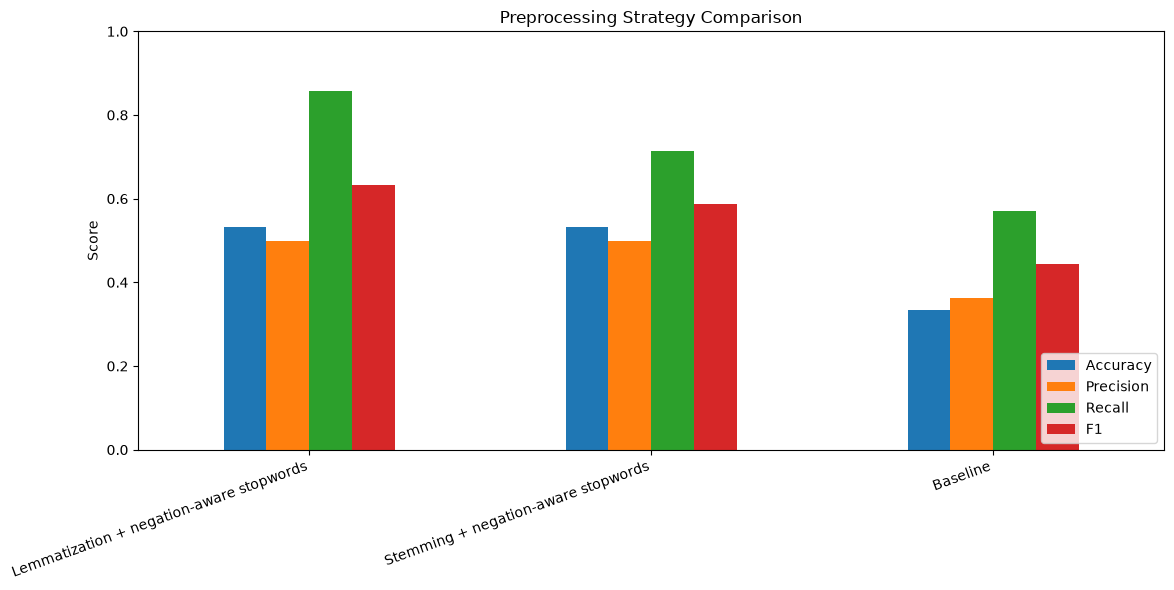

In [24]:
ax = results_df.set_index("Experiment")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
)

ax.set_title("Preprocessing Strategy Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 11.3 Inspect the best experiment's confusion matrix

Best experiment on this particular split: Lemmatization + negation-aware stopwords
\nClassification report:
              precision    recall  f1-score   support

    Negative       0.67      0.25      0.36         8
    Positive       0.50      0.86      0.63         7

    accuracy                           0.53        15
   macro avg       0.58      0.55      0.50        15
weighted avg       0.59      0.53      0.49        15



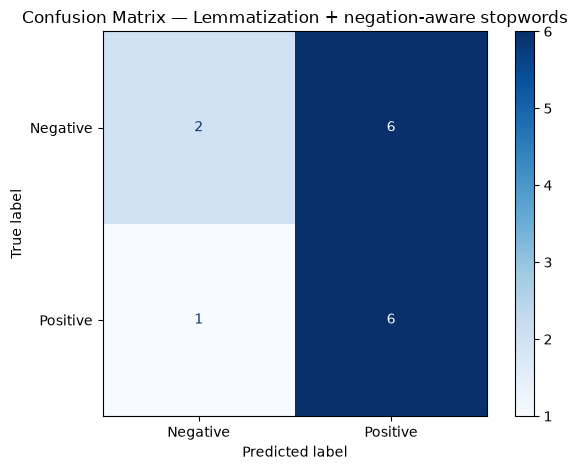

In [25]:
best_name = results_df.iloc[0]["Experiment"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Best experiment on this particular split:", best_name)
print("\\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0,
))

cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 11.4 Test new reviews

In [26]:
new_reviews = [
    "The product is excellent and works perfectly",
    "The delivery was terrible and the product is bad",
    "The quality is good but the service was not helpful",
    "I am not disappointed with this purchase",
]

for review in new_reviews:
    prediction = best_model.predict([review])[0]
    probabilities = best_model.predict_proba([review])[0]
    classes = list(best_model.named_steps["classifier"].classes_)
    positive_probability = float(probabilities[classes.index(1)])

    print("\\nReview:", review)
    print("Predicted sentiment:", "Positive" if prediction == 1 else "Negative")
    print("Positive-class probability:", round(positive_probability, 4))

\nReview: The product is excellent and works perfectly
Predicted sentiment: Positive
Positive-class probability: 0.6226
\nReview: The delivery was terrible and the product is bad
Predicted sentiment: Negative
Positive-class probability: 0.4492
\nReview: The quality is good but the service was not helpful
Predicted sentiment: Positive
Positive-class probability: 0.548
\nReview: I am not disappointed with this purchase
Predicted sentiment: Negative
Positive-class probability: 0.3941


## 11.5 Save the complete fitted pipeline

Saving the complete pipeline ensures that the fitted TF-IDF vocabulary, IDF values, tokenizer, and classifier are preserved together.

Only load trusted joblib files.

In [27]:
os.makedirs("artifacts", exist_ok=True)

model_path = "artifacts/nlp_preprocessing_sentiment_pipeline.joblib"
joblib.dump(best_model, model_path)

print("Saved:", model_path)

loaded_model = joblib.load(model_path)

sample = "The quality is excellent and the delivery was fast."
print("Reloaded model prediction:", loaded_model.predict([sample])[0])

PicklingError: Can't pickle <function make_tokenizer.<locals>.tokenizer at 0x000001FA619A8540>: it's not found as __main__.make_tokenizer.<locals>.tokenizer

# 12. Results interpretation and industry lessons

## How should you interpret the experiment?

Do not automatically choose the experiment with the highest score from a tiny dataset. Instead, ask:

1. Did preprocessing improve the metric consistently across multiple splits?
2. Did it preserve negation and important phrases?
3. Did it reduce vocabulary size?
4. Did it improve inference latency?
5. Did it introduce errors by collapsing different word forms?
6. Does it generalize to reviews from a different source or time period?

For a serious comparison, use cross-validation on training data, reserve a final test set, and evaluate on a larger, representative dataset.

## Industry use cases

| Technique | Example use |
|---|---|
| Tokenization | Search indexing, chat analysis, document parsing |
| Stemming | Lightweight keyword retrieval and search normalization |
| Lemmatization | Linguistically meaningful normalization in text analytics |
| Stopword filtering | Search/index optimization when frequent terms add little value |

## Production pitfalls

- Apply the same preprocessing at training and inference.
- Preserve negation for sentiment and intent tasks.
- Do not blindly remove punctuation, emojis, URLs, or numbers.
- Consider language-specific tokenizers and stopword lists.
- Monitor changes in user language and domain vocabulary.
- Keep raw text when possible so preprocessing decisions can be revisited.
- Treat preprocessing as an experiment, not a fixed checklist.

# 13. Interview questions

Try answering before expanding the answers.

### Q1. What is tokenization?
Tokenization divides text into smaller units such as sentences, words, subwords, or characters.

### Q2. What is the difference between stemming and lemmatization?
Stemming uses heuristic rules to produce stems that may not be valid words. Lemmatization uses lexical and grammatical information to produce dictionary base forms.

### Q3. Why does lemmatization benefit from POS tagging?
A word's grammatical role affects its lemma. POS information helps select the appropriate lexical form.

### Q4. Why can stopword removal hurt sentiment analysis?
Removing negation words such as `not` or `never` can reverse or obscure the sentiment.

### Q5. Is stemming always better than lemmatization because it is faster?
No. Speed is only one consideration. Linguistic quality, task performance, and domain vocabulary matter.

### Q6. Should we always lowercase text?
No. Case can carry meaning, such as distinguishing acronyms, named entities, and ordinary words.

### Q7. Should preprocessing be applied to test data?
Yes, using the exact transformations learned or configured from training. But data-dependent fitting (such as learning the TF-IDF vocabulary and IDF values) must happen on training data only.

### Q8. Do modern Transformers need the same preprocessing?
Usually not. They use their own tokenizer, often a subword tokenizer, and generally expect text in a model-specific format. Avoid applying aggressive stemming or stopword removal unless the model/task specifically calls for it.

# 14. Final mental model

```text
                    RAW TEXT
                       |
                       v
                  TOKENIZATION
             "playing cats" -> tokens
                       |
          +------------+-------------+
          |            |             |
          v            v             v
       STEMMING    LEMMATIZATION  STOPWORD FILTER
       playing       playing       remove selected
         ->           ->             frequent words
        play          play
          |            |             |
          +------------+-------------+
                       |
                       v
             PROCESSED TOKEN SEQUENCE
                       |
                       v
                 TF-IDF / BoW
                       |
                       v
                ML CLASSIFIER
                       |
                       v
                  EVALUATION
```

Remember the distinctions:

- **Tokenization:** Where should text be split?
- **Stemming:** What stem does a rule-based algorithm produce?
- **Lemmatization:** What is the dictionary base form, given grammatical information?
- **Stopword removal:** Which frequent words, if any, can safely be omitted for this task?

The most important practical lesson: **preserve meaning first; simplify text only when experiments show that the simplification helps.**

## Next topic

**POS Tagging** — we will learn how to identify nouns, verbs, adjectives, adverbs, and other grammatical categories, and why POS tagging is useful for lemmatization, information extraction, and NLP pipelines.